In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler

In [ ]:
df = pd.read_csv('song_recomendation_A.csv')
df.head()

,Track URI,Track Name,Artist Name(s),Album Name,Album Release Date,Popularity,Artist Genres,Danceability,Energy,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Time Signature
0,spotify:track:38tpcZDofjtDNunMm5w1EU,If I Could Change Your Mind,HAIM,Days Are Gone (Deluxe Edition),2013-01-01,53,"indietronica,metropopolis",0.671,0.852,2.0,-5.557,0.0,0.0425,0.01840,0.000099,0.0841,0.737,125.043,4.0
1,spotify:track:60lJebAiPbIrnLeGev6kHX,If I Ain't Got You,Alicia Keys,The Diary Of Alicia Keys,2003,0,"neo soul,pop,r&b",0.589,0.449,7.0,-9.153,1.0,0.1050,0.60700,0.000022,0.1000,0.159,118.351,3.0
2,spotify:track:1dbt3sOwRmUOLfQZSpSz9O,Truly,Lionel Richie,Lionel Richie (Expanded Edition),1982,0,soft rock,0.366,0.238,1.0,-13.853,1.0,0.0381,0.64600,0.000010,0.0876,0.131,68.362,4.0
3,spotify:track:50PeqUz1BjMw9ayNTk5O4d,I've Been Thinking About You,Londonbeat,Best! The Singles 16 Tracks,1995-11-20,69,"eurodance,hip house",0.678,0.659,11.0,-12.695,0.0,0.0396,0.02360,0.001920,0.0744,0.899,113.542,4.0
4,spotify:track:111P8I22TrLyxQm7Jcwdoy,Kung Fu Fighting,"Bus Stop, Carl Douglas",The Soul of the Kung Fu Fighter,1972-02-13,0,NaN,0.737,0.855,11.0,-10.319,0.0,0.0646,0.00475,0.000017,0.1630,0.583,116.023,4.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Track URI           5000 non-null   object 
 1   Track Name          4999 non-null   object 
 2   Artist Name(s)      4999 non-null   object 
 3   Album Name          4999 non-null   object 
 4   Album Release Date  5000 non-null   object 
 5   Popularity          5000 non-null   int64  
 6   Artist Genres       4705 non-null   object 
 7   Danceability        5000 non-null   float64
 8   Energy              5000 non-null   float64
 9   Key                 5000 non-null   float64
 10  Loudness            5000 non-null   float64
 11  Mode                5000 non-null   float64
 12  Speechiness         5000 non-null   float64
 13  Acousticness        4850 non-null   float64
 14  Instrumentalness    5000 non-null   float64
 15  Liveness            5000 non-null   float64
 16  Valenc

In [ ]:
df.isna().sum()

,0
Track Name,0
Artist Name(s),0
Album Name,0
Popularity,0
Artist Genres,0
Danceability,0
Energy,0
Key,0
Loudness,0
Mode,0


In [ ]:
df = df.drop(columns=['Track URI','Album Release Date'])

In [ ]:
df = df.dropna(subset=['Track Name'])

In [ ]:
cols = ['Track Name','Artist Name(s)','Album Name','Artist Genres']
for col in cols:
  print(df[col].value_counts())

Track Name
One                               6
Last Night                        6
Higher                            5
How Deep Is Your Love             5
Stay                              5
                                 ..
Cinnamon                          1
STAY (with Justin Bieber)         1
Princess of China - Radio Edit    1
Something So Strong               1
Burning Down The House            1
Name: count, Length: 4510, dtype: int64
Artist Name(s)
Elvis Presley                                                                  27
P!nk                                                                           25
Taylor Swift                                                                   22
Ed Sheeran                                                                     21
Bee Gees                                                                       19
                                                                               ..
Gloria Estefan, Miami Sound Machine           

In [ ]:
num = df.select_dtypes(include=['int64','float64']).columns

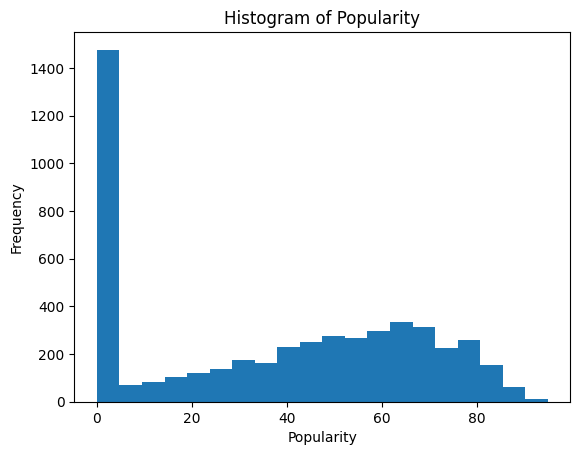

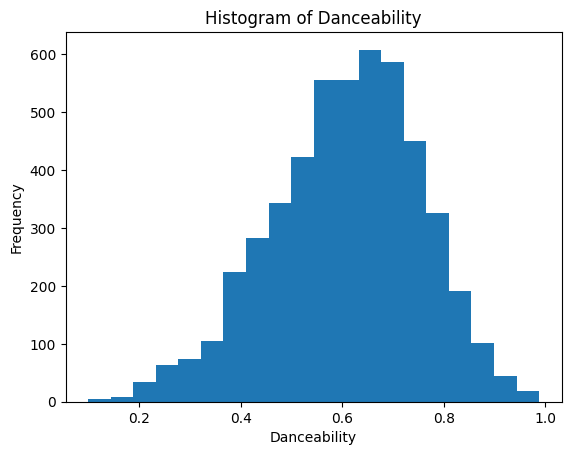

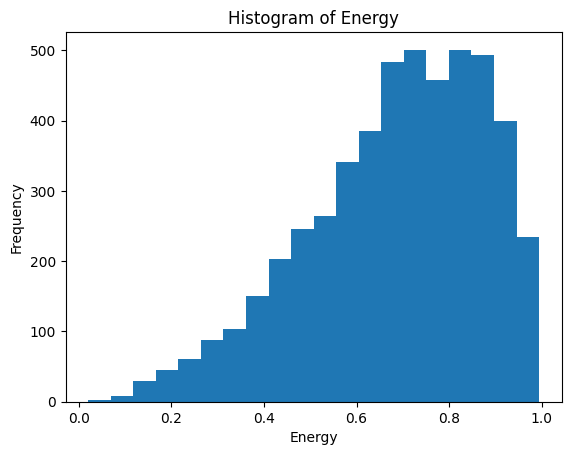

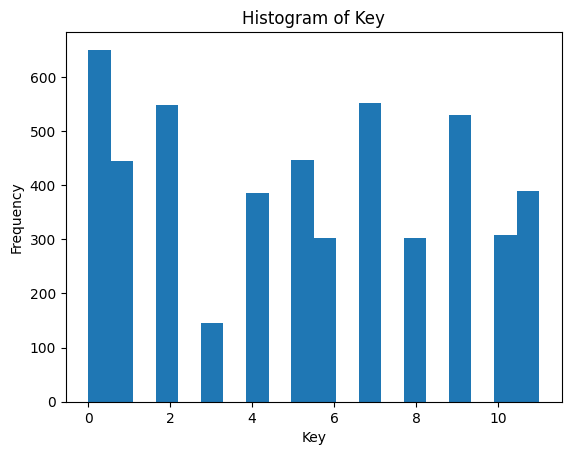

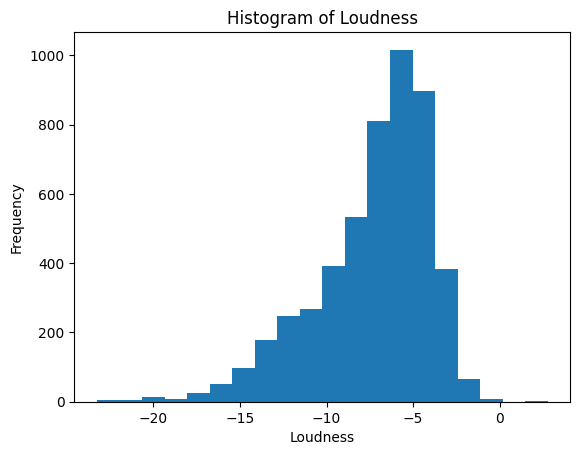

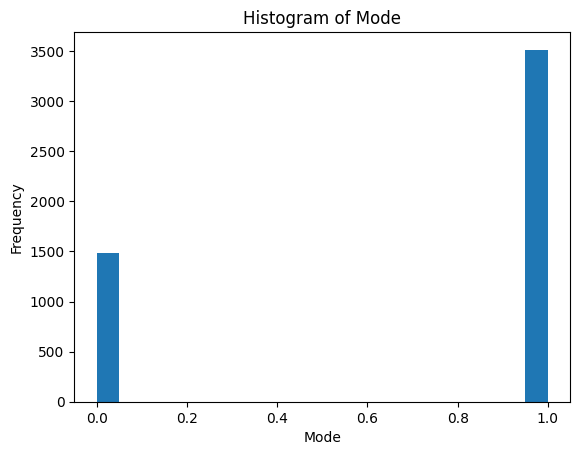

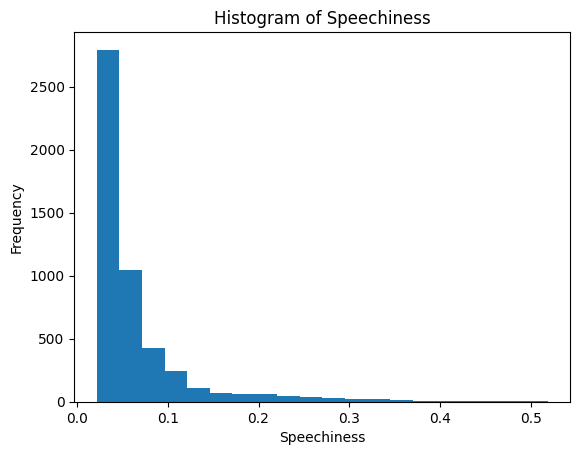

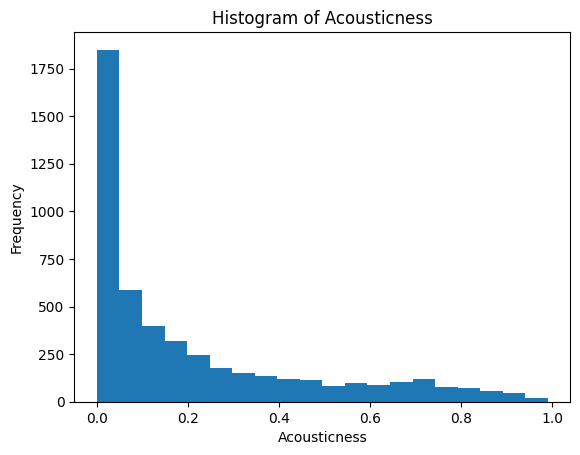

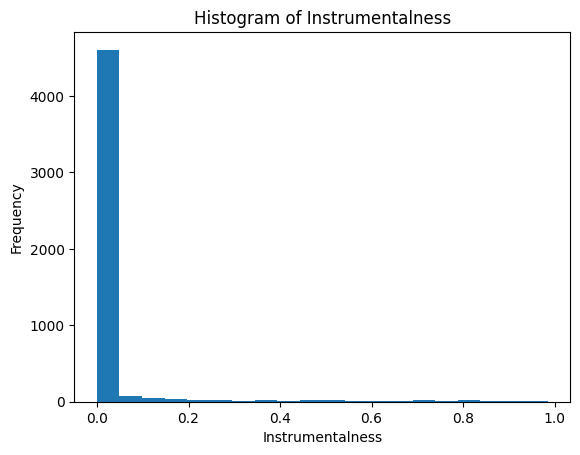

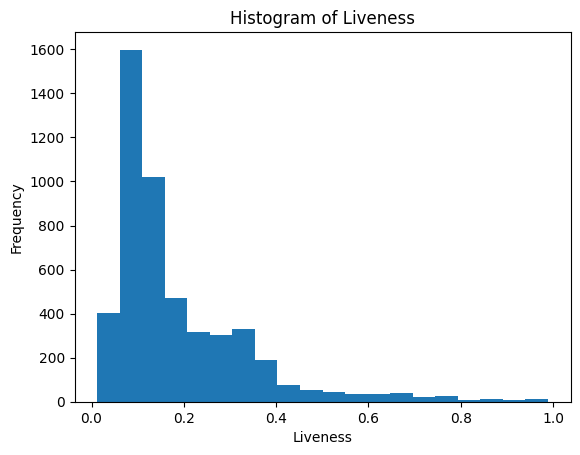

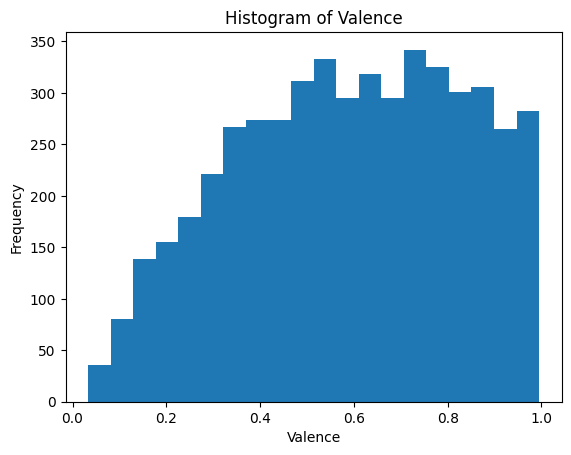

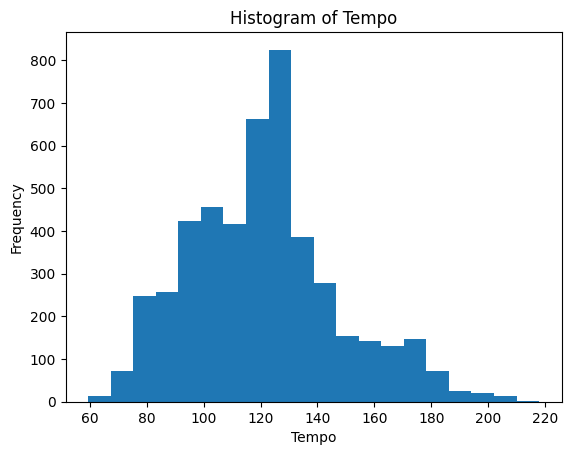

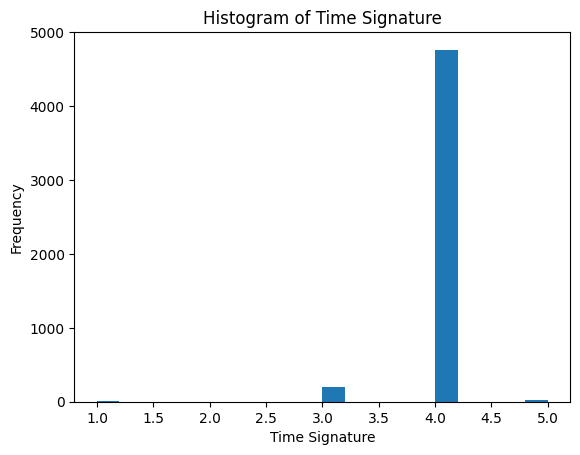

In [ ]:
for col in num:
    plt.figure()
    plt.hist(df[col], bins=20)
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

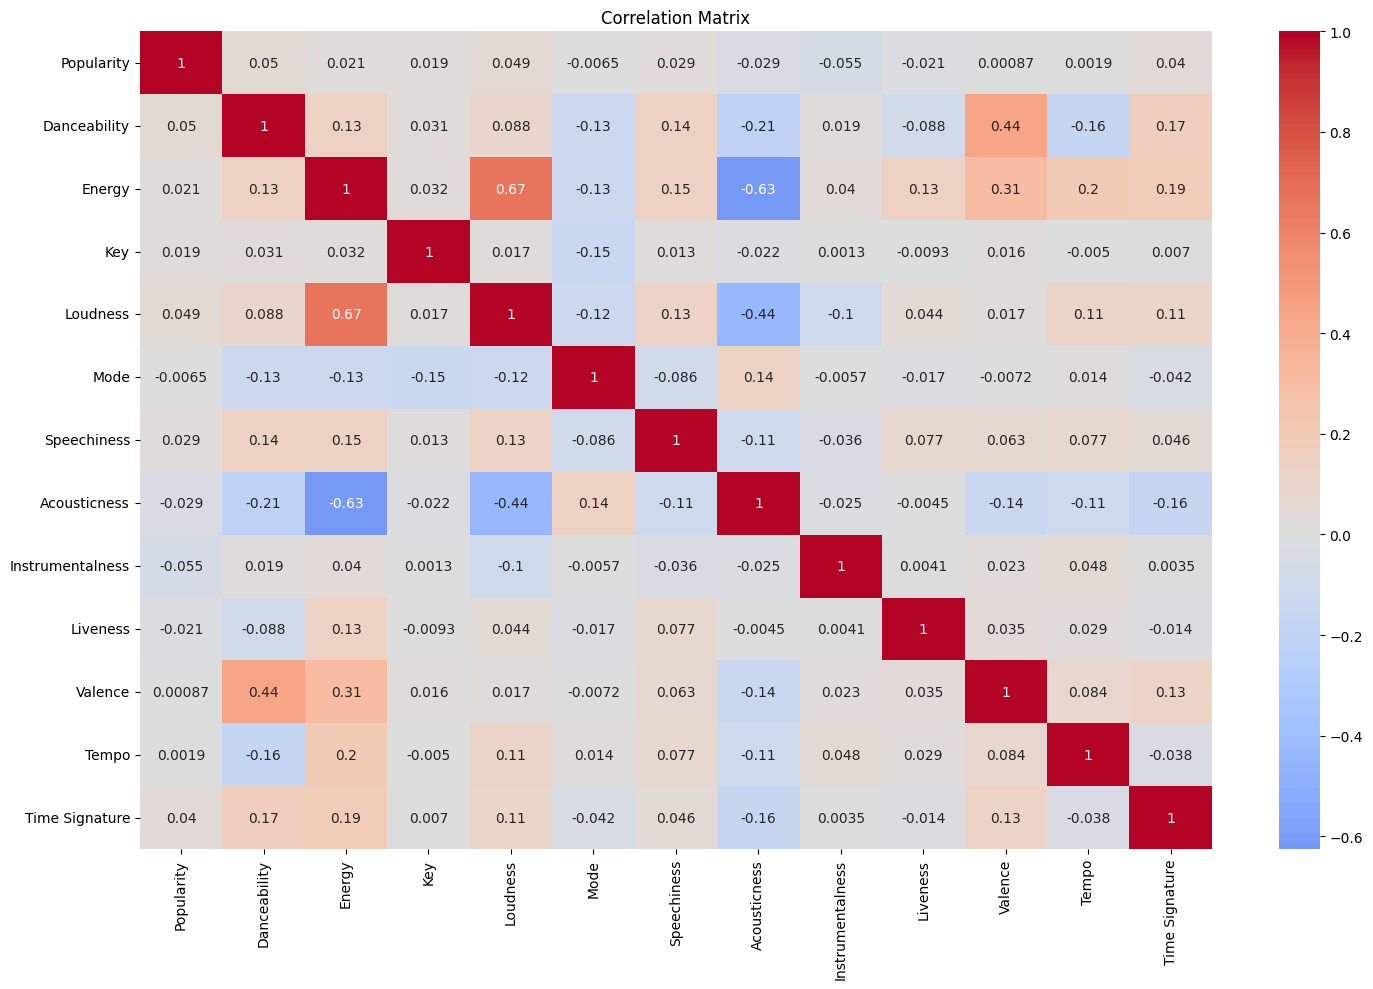

In [ ]:
df_temp = df.copy()

corr = df_temp[num].corr()
plt.figure(figsize=(15,10))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()


In [ ]:
df['Artist Genres'] = (
    df.groupby('Artist Name(s)')['Artist Genres']
      .transform(lambda x: x.ffill().bfill())
)
df['Artist Genres'] = df['Artist Genres'].fillna('Unknown')

/tmp/ipython-input-1146698662.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .transform(lambda x: x.ffill().bfill())


In [ ]:
df['Tempo'] = df['Tempo'].fillna(df['Tempo'].median())

In [ ]:
df['Acousticness'] = df['Acousticness'].fillna(df['Acousticness'].median())

In [ ]:
df['Artist Genres'] = df['Artist Genres'].str.replace(',', ' ')

In [ ]:
df['Artist Name(s)'] = (
    df['Artist Name(s)']
    .str.lower()
    .str.replace(',', ' ')
    .str.replace('&', ' ')
)

In [ ]:
df['text_features'] = (
    df['Track Name'].fillna('') + ' ' +
    df['Artist Name(s)'].fillna('') + ' ' +
    df['Artist Genres'].fillna('')
).str.lower()

In [ ]:
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(df['text_features'])

In [ ]:
audio_features = ['Danceability','Energy','Loudness','Speechiness','Acousticness','Instrumentalness','Liveness','Valence','Tempo','Popularity']

In [ ]:
scaler = StandardScaler()
num_scaled = scaler.fit_transform(df[audio_features])

In [ ]:
from scipy.sparse import hstack
feature_matrix = hstack([num_scaled, tfidf_matrix])
similarity = cosine_similarity(feature_matrix)

In [ ]:
df['track_name_clean']  = df['Track Name'].str.lower().str.strip()
df['artist_name_clean'] = df['Artist Name(s)'].str.lower().str.strip()
df['album_name_clean']  = df['Album Name'].str.lower().str.strip()

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def recommend(input, top_n=5):
    input = input.lower().strip()

    if input in df['artist_name_clean'].values:
        artist_idx = df[df['artist_name_clean'] == input].index

        result = (
            df.loc[artist_idx]
              .sort_values(by='Popularity', ascending=False)
              .head(top_n)
        )

        return result[['Track Name', 'Artist Name(s)', 'Album Name', 'Popularity']]

    elif input in df['album_name_clean'].values:
        album_idx = df[df['album_name_clean'] == input].index

        return df.loc[album_idx][
            ['Track Name', 'Artist Name(s)', 'Album Name', 'Popularity']
        ].head(top_n)

    elif df['track_name_clean'].eq(input).any():
        exact_idx = df[df['track_name_clean'] == input].index[0]

        return df.loc[[exact_idx],
            ['Track Name', 'Artist Name(s)', 'Album Name', 'Popularity']
        ]

    elif df['track_name_clean'].str.contains(input, na=False).any():
        base_idx = df[
            df['track_name_clean'].str.contains(input, na=False)
        ].index[0]

        base_audio = num_scaled[base_idx].reshape(1, -1)
        audio_sim = cosine_similarity(base_audio, num_scaled)[0]

        final_idx = np.argsort(audio_sim)[::-1][1:top_n+1]

        return df.loc[final_idx][
            ['Track Name', 'Artist Name(s)', 'Album Name', 'Popularity']
        ]

    else:
        user_vec = tfidf.transform([input])
        text_sim = cosine_similarity(user_vec, tfidf_matrix)[0]

        top_text_idx = np.argsort(text_sim)[::-1][:20]
        candidate_audio = num_scaled[top_text_idx]

        base_audio = candidate_audio.mean(axis=0).reshape(1, -1)
        audio_sim = cosine_similarity(base_audio, candidate_audio)[0]

        final_idx = top_text_idx[
            np.argsort(audio_sim)[::-1][:top_n]
        ]

        return df.loc[final_idx][
            ['Track Name', 'Artist Name(s)', 'Album Name', 'Popularity']
        ]

In [ ]:
recommend('mariah carey')

,Track Name,Artist Name(s),Album Name,Popularity
327,Fantasy,mariah carey,Daydream,80
2186,Love Takes Time,mariah carey,#1 to Infinity,28
1869,Shake It Off,mariah carey,The Emancipation of Mimi (Ultra Platinum Edition),0
3492,Don't Forget About Us,mariah carey,The Emancipation of Mimi (Ultra Platinum Edition),0
3735,We Belong Together,mariah carey,The Emancipation of Mimi (Ultra Platinum Edition),0


In [ ]:
recommend('Daydream')

,Track Name,Artist Name(s),Album Name,Popularity
327,Fantasy,mariah carey,Daydream,80
1374,One Sweet Day,mariah carey boyz ii men,Daydream,71


In [ ]:
recommend('red')

,Track Name,Artist Name(s),Album Name,Popularity
1599,22,taylor swift,Red,0
3554,Begin Again,taylor swift,Red,61
4596,Everything Has Changed,taylor swift ed sheeran,Red,0


In [ ]:
recommend('upbeat')

,Track Name,Artist Name(s),Album Name,Popularity
22,The Horses,daryl braithwaite,Rise,63
4996,Moody River,pat boone,The Gold Collection,27
26,All My Lovin,johnny young kompany,Step Back With,16
19,I Miss You (feat. Julia Michaels),clean bandit julia michaels,I Miss You (feat. Julia Michaels),0
24,Is She Really Going Out With Him?,joe jackson,Look Sharp!,62
